# Feature quality

Inspect measurement distributions and preprocessing needs. Set `COHORTS` to select years.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.eda.io import load_tasks, cohort_tables

COHORTS = None  # Discover all years; use ["1year"] or ["2year", "3year"] to restrict.
tables = load_tasks(ROOT / "data", cohorts=COHORTS)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
print("Loaded task files by cohort:", {c: len(g) for c, g in cohort_tables(tables).items()})


Loaded task files by cohort: {'1year': 21, '2year': 21, '3year': 18}


In [2]:
from src.eda.features import feature_quality
from src.eda.plotting import plot_representative_distributions

features = feature_quality(tables)
display(features.quality.groupby(["cohort", "scope"], sort=False).agg(
    feature_task_pairs=("feature", "size"), missing_cells=("missing", "sum"),
    invalid_numeric_cells=("invalid_numeric", "sum"), infinite_cells=("infinite", "sum"),
    zero_cells=("zero", "sum"), constant_pairs=("constant", "sum"),
    near_constant_pairs=("near_constant", "sum"), potential_extreme_cells=("potential_extreme_values", "sum"),
))


feature_task_pairs  missing_cells  \
cohort scope                                                  
1year  raw                               630              0   
       valid_labels_only                 630              0   
2year  raw                               630              0   
       valid_labels_only                 630              0   
3year  raw                               540              0   
       valid_labels_only                 540              0   

                          invalid_numeric_cells  infinite_cells  zero_cells  \
cohort scope                                                                  
1year  raw                                    0               0        5303   
       valid_labels_only                      0               0        3729   
2year  raw                                    0               0       20872   
       valid_labels_only                      0               0        4491   
3year  raw                                    0               0       17603   
       valid_labels_only                      0               0        4017   

                          constant_pairs  near_constant_pairs  \
cohort scope                                                    
1year  raw                             0                    0   
       valid_labels_only               0                    0   
2year  raw                             0                    0   
       valid_labels_only               0                    0   
3year  raw                             0                    2   
       valid_labels_only               0                    2   

                          potential_extreme_cells  
cohort scope                                       
1year  raw                                   1422  
       valid_labels_only                     1093  
2year  raw                                   2991  
       valid_labels_only                     1223  
3year  raw                                   3005  
       valid_labels_only                     1441

Summaries cover raw rows and labels `{0, 1, 2}`. Percentiles use finite values; zeros remain measurements. Near-constant features meet the modal-fraction threshold. IQR fences flag values for review, especially when the IQR is zero.

In [3]:
display(features.statistics[["cohort", "task", "scope", "feature", "minimum", "p01", "median", "iqr", "p99", "maximum"]].head(12))
constant = features.quality.loc[features.quality.constant | features.quality.near_constant]
display(constant[["cohort", "task", "scope", "feature", "constant", "modal_fraction", "near_constant_threshold"]].head(20))
print("Constant or near-constant feature/task/scope entries:", len(constant))


,cohort,task,scope,feature,minimum,p01,median,iqr,p99,maximum
0,1year,Task_1,raw,mean:pressure,0.0,4479.076088,22590.317690,9048.961275,30979.545427,32422.66947
1,1year,Task_1,raw,std:pressure,0.0,2773.397277,7531.502740,1946.843745,9983.978155,10296.20770
2,1year,Task_1,raw,iqr:pressure,0.0,259.350000,9154.000000,5173.250000,18815.700000,20036.00000
3,1year,Task_1,raw,mean:tilt(on-surface),0.0,0.002755,0.103825,0.109983,0.498492,0.54546
4,1year,Task_1,raw,std:tilt(on-surface),0.0,0.000307,0.518580,0.311323,1.318205,1.44634
5,1year,Task_1,raw,iqr:tilt(on-surface),0.0,0.000206,0.000880,0.000822,0.012339,0.03772
6,1year,Task_1,raw,writing_duration(on-surface),0.0,9.633750,48.152500,34.496250,143.008050,162.89500
7,1year,Task_1,raw,writing_duration_overall,0.0,18.743050,69.737500,49.938750,204.643950,235.21000
8,1year,Task_1,raw,number_of_interruptions,0.0,6.340000,48.000000,32.000000,139.760000,264.00000
9,1year,Task_1,raw,writing_width(on-surface),0.0,0.574600,4.005000,3.100000,17.806100,19.20000


,cohort,task,scope,feature,constant,modal_fraction,near_constant_threshold
3149,3year,Task_11,raw,average_normalized_jerk,False,0.986207,0.95
3179,3year,Task_11,valid_labels_only,average_normalized_jerk,False,0.983051,0.95
3569,3year,Task_18,raw,average_normalized_jerk,False,0.965517,0.95
3599,3year,Task_18,valid_labels_only,average_normalized_jerk,False,0.957627,0.95


Constant or near-constant feature/task/scope entries: 4


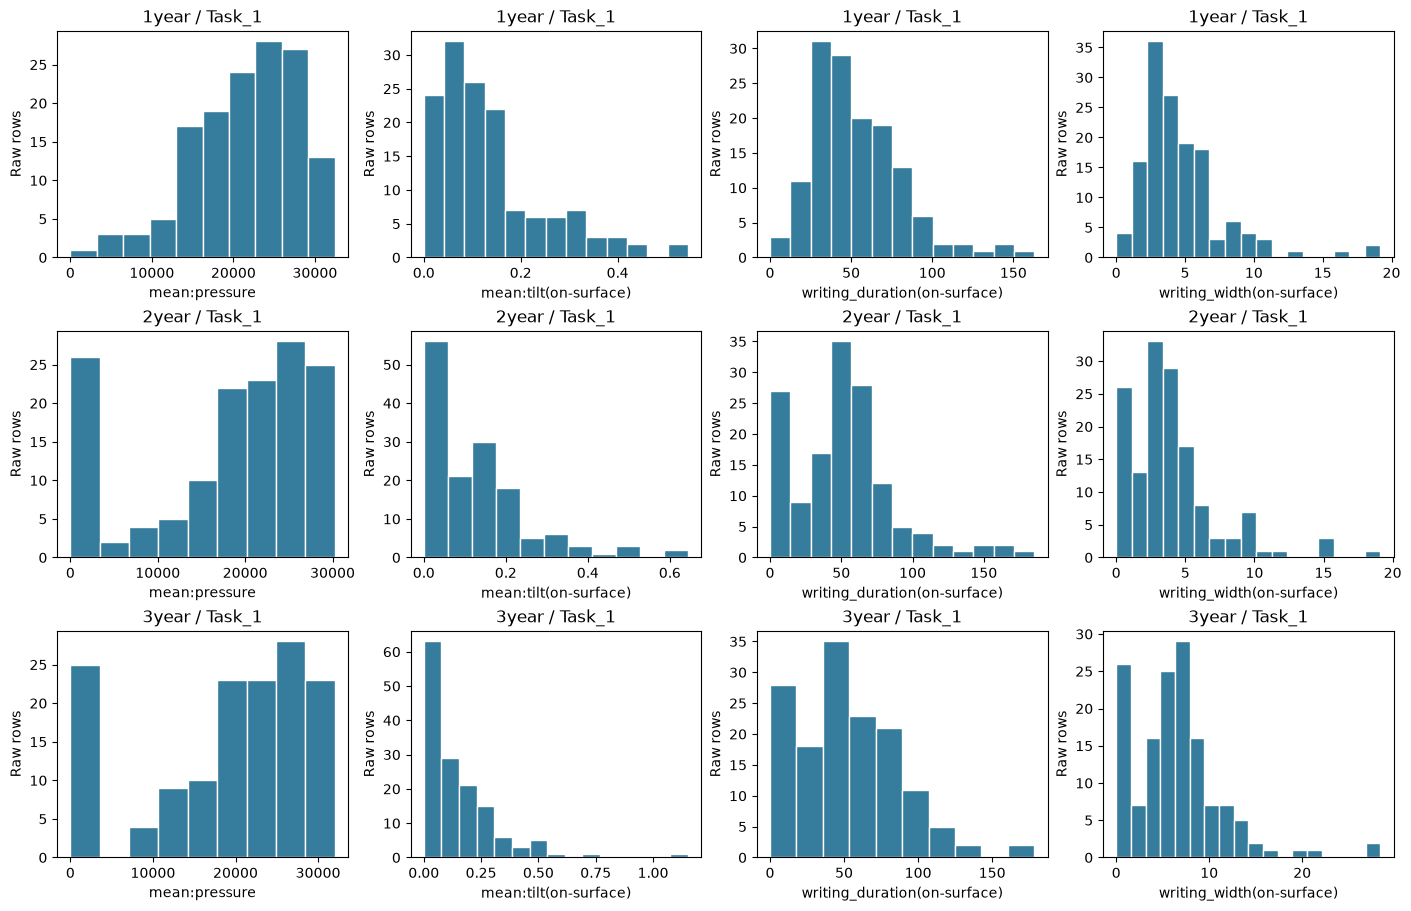

In [4]:
plot_representative_distributions(tables, task_index=0)
plt.show()


In [5]:
display(features.measurements.groupby(["cohort", "issue"], sort=False)[["rows", "valid_label_rows", "evaluable_rows"]].sum())
display(features.measurements.loc[features.measurements.issue.eq("duplicate_feature_columns"),
                                   ["cohort", "task", "scope", "detail"]].head(20))
high_zero = features.quality.sort_values("zero_fraction", ascending=False)
display(high_zero[["cohort", "task", "scope", "feature", "zero", "finite_values", "zero_fraction"]].head(12))


rows  valid_label_rows  \
cohort issue                                                       
1year  all_zero_measurements                21                 0   
       no_finite_measurements                0                 0   
       overall_duration_below_on_surface     0                 0   
2year  all_zero_measurements               547                 1   
       no_finite_measurements                0                 0   
       overall_duration_below_on_surface     0                 0   
3year  all_zero_measurements               450                 0   
       no_finite_measurements                0                 0   
       overall_duration_below_on_surface     0                 0   

                                          evaluable_rows  
cohort issue                                              
1year  all_zero_measurements                        2935  
       no_finite_measurements                       2935  
       overall_duration_below_on_surface            2935  
2year  all_zero_measurements                        3045  
       no_finite_measurements                       3045  
       overall_duration_below_on_surface            3045  
3year  all_zero_measurements                        2610  
       no_finite_measurements                       2610  
       overall_duration_below_on_surface            2610

,cohort,task,scope,detail


,cohort,task,scope,feature,zero,finite_values,zero_fraction
3149,3year,Task_11,raw,average_normalized_jerk,143,145,0.986207
3179,3year,Task_11,valid_labels_only,average_normalized_jerk,116,118,0.983051
3569,3year,Task_18,raw,average_normalized_jerk,140,145,0.965517
3599,3year,Task_18,valid_labels_only,average_normalized_jerk,113,118,0.957627
3509,3year,Task_17,raw,average_normalized_jerk,137,145,0.944828
3539,3year,Task_17,valid_labels_only,average_normalized_jerk,111,118,0.940678
3269,3year,Task_13,raw,average_normalized_jerk,136,145,0.937931
3209,3year,Task_12,raw,average_normalized_jerk,134,145,0.924138
3299,3year,Task_13,valid_labels_only,average_normalized_jerk,108,117,0.923077
3239,3year,Task_12,valid_labels_only,average_normalized_jerk,108,118,0.915254


In [6]:
display(features.decisions.groupby(["cohort", "scope"], sort=False).agg(
    tasks_needing_missingness_review=("median_imputation_may_be_needed", "sum"),
    tasks_with_scaling_to_test=("robust_scaling_worth_testing", "sum"),
    largest_magnitude_ratio=("finite_median_magnitude_ratio", "max"),
    manual_review_task_rows=("manual_review_rows", "sum"),
))


tasks_needing_missingness_review  \
cohort scope                                                 
1year  raw                                               0   
       valid_labels_only                                 0   
2year  raw                                               0   
       valid_labels_only                                 0   
3year  raw                                               0   
       valid_labels_only                                 0   

                          tasks_with_scaling_to_test  largest_magnitude_ratio  \
cohort scope                                                                    
1year  raw                                        21             7.830321e+07   
       valid_labels_only                          21             7.953033e+07   
2year  raw                                        21             1.417397e+08   
       valid_labels_only                          21             5.765174e+07   
3year  raw                                        18             1.868450e+08   
       valid_labels_only                          18             1.529982e+08   

                          manual_review_task_rows  
cohort scope                                       
1year  raw                                     21  
       valid_labels_only                        0  
2year  raw                                    547  
       valid_labels_only                        1  
3year  raw                                    450  
       valid_labels_only                        0

Review zero-heavy features and duration violations before choosing preprocessing. Units may explain scale differences. Fit imputation, scaling, and feature removal within training folds. Flag counts overlap and do not count unique subjects.